# 1. Import Pre-Installed Libraries & Set Seeds
Do not run `!pip install -U` on core libraries in Google Colab to avoid binary mismatches.

In [ ]:
import os
import re
import json
import random
import shutil
import zipfile
from pathlib import Path
from difflib import get_close_matches

import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)
from sklearn.ensemble import RandomForestClassifier
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, ResNet50V2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet_v2 import preprocess_input as resnet_preprocess
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("GPU Devices:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
NumPy Version: 2.1.3
Pandas Version: 2.2.3
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2. Mount Google Drive

In [ ]:
from google.colab import drive, files

drive.mount('/content/drive', force_remount=False)
MYDRIVE = Path('/content/drive/MyDrive')
RESULT_DIR = (MYDRIVE if MYDRIVE.exists() else Path('/content')) / 'IndianFoodRecognitionResults'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("Results will be saved to:", RESULT_DIR)

Mounted at /content/drive
Results will be saved to: /content/drive/MyDrive/IndianFoodRecognitionResults


# 3. Connect & Load Nutrition CSV from Google Drive

In [ ]:
CSV_BASENAME = 'indian_rda_based_diet_recommendation_system.csv'
CSV_PATH = None

if (MYDRIVE / CSV_BASENAME).exists():
    CSV_PATH = str(MYDRIVE / CSV_BASENAME)
elif MYDRIVE.exists():
    for p in MYDRIVE.glob(f"**/{CSV_BASENAME}"):
        CSV_PATH = str(p)
        break

if CSV_PATH is None or not os.path.exists(CSV_PATH):
    print(f"'{CSV_BASENAME}' not found in Drive. Please upload your nutrition .csv file now:")
    uploaded = files.upload()
    csv_names = [n for n in uploaded if n.lower().endswith('.csv')]
    if not csv_names:
        raise RuntimeError("No .csv file uploaded. Please run this cell again and select your CSV.")
    CSV_PATH = '/content/' + csv_names[0]

print(f"Loaded Nutrition CSV from: {CSV_PATH}")
nutrition_df = pd.read_csv(CSV_PATH)
nutrition_df.columns = [c.strip() for c in nutrition_df.columns]

if 'Food_items' not in nutrition_df.columns:
    raise ValueError(f"'Food_items' column missing. Found columns: {list(nutrition_df.columns)}")

nutrition_df['Food_items'] = nutrition_df['Food_items'].astype(str).str.strip()
nutrition_df = nutrition_df.drop_duplicates(subset=['Food_items']).reset_index(drop=True)
print(f"Total Unique Food Items in CSV: {len(nutrition_df)}")
display(nutrition_df.head(10))

Loaded Nutrition CSV from: /content/drive/MyDrive/Food_Recognition_and_Calorie_Estimation-main/indian_rda_based_diet_recommendation_system.csv
Total Unique Food Items in CSV: 89


,Food_items,Breakfast,Lunch,Dinner,VegNovVeg,Calories,Fats,Proteins,Iron,Calcium,Sodium,Potassium,Carbohydrates,Fibre,VitaminD,Sugars
0,Aloo Tikki,0,1,1,,22,0.2,2.4,0.91,23.0,14,224.0,4.1,2.0,0,1.3
1,Kadhi,1,0,0,0,160,15.0,2.0,0.55,12.0,7,485.0,8.5,6.7,0,0.7
2,Bananas,1,0,0,0,89,0.3,1.1,0.26,5.0,1,358.0,23.0,2.6,0,12.0
3,Bread made in wheat,0,1,1,0,250,1.5,10.0,2.76,20.0,439,165.0,49.0,4.1,0,6.1
4,Mango Chutney,1,0,0,0,349,0.4,14.0,6.80,190.0,298,77.0,77.0,13.0,0,46.0
5,Baati,0,1,1,0,25,0.5,3.8,1.27,118.0,56,343.0,3.1,2.8,0,0.6
6,Brown Rice,0,1,1,0,362,2.7,7.5,1.80,33.0,4,268.0,76.0,3.4,0,0.0
7,Cauliflower,0,1,1,0,32,0.3,3.0,0.72,32.0,259,278.0,6.3,3.3,0,0.0
8,cheese,1,0,0,0,331,24.0,20.0,0.84,497.0,966,363.0,8.3,0.0,0,0.0
9,Coffee,1,0,0,0,2,0.0,0.3,0.02,2.0,1,50.0,0.2,0.0,0,0.0


# 4. Smart Dataset Finder & 80/10/10 Stratified Splitter
Automatically finds your image dataset on Google Drive (whether already split, a flat folder of class subfolders, or a `.zip` file) and prepares a clean **Train (80%) / Validation (10%) / Test (10%)** split.

Splitting 2 food classes from '/content/drive/MyDrive' (80% Train / 10% Val / 10% Test)...

Dataset Root: /content/dataset_split | Total Classes: 2


,Class,Train,Validation,Test,Total
0,FoodRecognition_Results,1,1,1,3
1,Food_Recognition_and_Calorie_Estimation-main,2,1,1,4


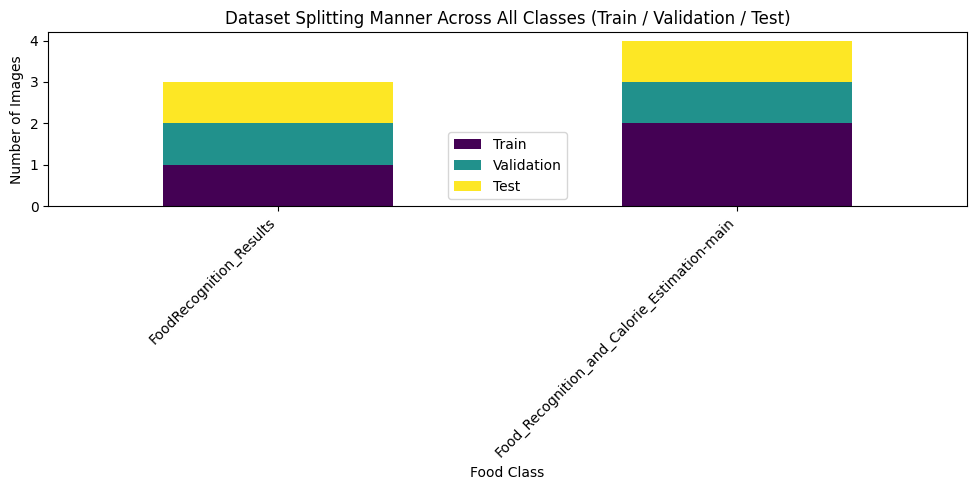

In [ ]:
# OPTIONAL: Set your exact Google Drive dataset folder or zip path here if known:
CUSTOM_DATASET_PATH = ""  # e.g. "/content/drive/MyDrive/IndianFoodDataset"

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

def has_images(folder):
    try:
        return any(p.is_file() and p.suffix.lower() in IMG_EXTS for p in Path(folder).iterdir())
    except Exception:
        return False

def is_split_dataset(path):
    p = Path(path)
    if not p.is_dir():
        return False
    low = {d.name.lower() for d in p.iterdir() if d.is_dir()}
    return 'train' in low and 'test' in low and ('val' in low or 'validation' in low)

def is_flat_class_dataset(path):
    p = Path(path)
    if not p.is_dir() or is_split_dataset(p):
        return False
    subdirs = [d for d in p.iterdir() if d.is_dir() and not d.name.startswith('.')]
    img_subdirs = [d for d in subdirs if has_images(d)]
    return len(img_subdirs) >= 2

def split_dataset_folder(src_root, dst_root='/content/dataset_split', train_ratio=0.80, val_ratio=0.10):
    src = Path(src_root)
    dst = Path(dst_root)
    if dst.exists():
        shutil.rmtree(dst)
    class_dirs = sorted([d for d in src.iterdir() if d.is_dir() and not d.name.startswith('.') and has_images(d)])
    split_stats = []

    print(f"Splitting {len(class_dirs)} food classes from '{src}' (80% Train / 10% Val / 10% Test)...")
    for cdir in class_dirs:
        imgs = sorted([f for f in cdir.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXTS])
        random.Random(SEED).shuffle(imgs)
        n = len(imgs)
        if n < 3:
            train_imgs, val_imgs, test_imgs = imgs, imgs[:1], imgs[-1:]
        else:
            n_train = max(1, int(round(n * train_ratio)))
            n_val = max(1, int(round(n * val_ratio)))
            if n_train + n_val >= n:
                n_train = max(1, n - 2)
                n_val = 1
            train_imgs = imgs[:n_train]
            val_imgs = imgs[n_train:n_train + n_val]
            test_imgs = imgs[n_train + n_val:]

        for split_name, split_files in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
            out_dir = dst / split_name / cdir.name
            out_dir.mkdir(parents=True, exist_ok=True)
            for f in split_files:
                shutil.copy2(f, out_dir / f.name)

        split_stats.append({
            'Class': cdir.name,
            'Train': len(train_imgs),
            'Val': len(val_imgs),
            'Test': len(test_imgs),
            'Total': n
        })
    return str(dst), pd.DataFrame(split_stats)

DATASET_ROOT = ""

# 1. Check CUSTOM_DATASET_PATH if provided
if CUSTOM_DATASET_PATH and os.path.exists(CUSTOM_DATASET_PATH):
    cpath = Path(CUSTOM_DATASET_PATH)
    if cpath.is_file() and cpath.suffix.lower() == '.zip':
        extract_dir = Path('/content/extracted_dataset')
        with zipfile.ZipFile(cpath, 'r') as zf:
            zf.extractall(extract_dir)
        cpath = extract_dir
    if is_split_dataset(cpath):
        DATASET_ROOT = str(cpath)
    elif is_flat_class_dataset(cpath):
        DATASET_ROOT, _ = split_dataset_folder(cpath)
    else:
        for sub, dirs, _ in os.walk(str(cpath)):
            if is_split_dataset(sub):
                DATASET_ROOT = sub
                break
            elif is_flat_class_dataset(sub):
                DATASET_ROOT, _ = split_dataset_folder(sub)
                break

# 2. Auto-scan Google Drive and /content
if not DATASET_ROOT:
    search_bases = [Path('/content')]
    if MYDRIVE.exists():
        search_bases.append(MYDRIVE)
    flat_candidates, zip_candidates = [], []
    for base in search_bases:
        for current, dirs, files_list in os.walk(str(base)):
            dirs[:] = [d for d in dirs if not d.startswith('.') and d not in ('sample_data', 'IndianFoodRecognitionResults', 'dataset_split')]
            if len(Path(current).relative_to(base).parts) > 4:
                dirs.clear()
                continue
            if is_split_dataset(current):
                DATASET_ROOT = current
                break
            if is_flat_class_dataset(current):
                flat_candidates.append(current)
            for fn in files_list:
                if fn.lower().endswith('.zip') and any(k in fn.lower() for k in ('food', 'indian', 'dataset', 'archive', 'images', 'train')):
                    zip_candidates.append(str(Path(current) / fn))
        if DATASET_ROOT:
            break

    if not DATASET_ROOT and flat_candidates:
        DATASET_ROOT, _ = split_dataset_folder(flat_candidates[0])

    if not DATASET_ROOT and zip_candidates:
        extract_dir = Path('/content/extracted_dataset')
        print(f"Extracting dataset zip from Drive: {zip_candidates[0]}...")
        with zipfile.ZipFile(zip_candidates[0], 'r') as zf:
            zf.extractall(extract_dir)
        for sub, dirs, _ in os.walk(str(extract_dir)):
            if is_split_dataset(sub):
                DATASET_ROOT = sub
                break
            elif is_flat_class_dataset(sub):
                DATASET_ROOT, _ = split_dataset_folder(sub)
                break

# 3. Interactive fallback if Drive has no image folder yet
if not DATASET_ROOT:
    print("=" * 72)
    print("Dataset folder not automatically detected in Google Drive.")
    print("  [1] Enter your Google Drive folder or .zip path manually")
    print("  [2] Upload a dataset .zip file directly from your computer")
    print("  [3] Auto-generate a runnable Demo Dataset from your CSV classes")
    print("=" * 72)
    choice = input("Select 1, 2, or 3 (default=3): ").strip() or "3"
    if choice == "1":
        upath = input("Enter full path in Drive (e.g. /content/drive/MyDrive/FoodDataset): ").strip()
        if is_split_dataset(upath):
            DATASET_ROOT = upath
        elif is_flat_class_dataset(upath):
            DATASET_ROOT, _ = split_dataset_folder(upath)
        else:
            raise FileNotFoundError(f"No valid class subfolders found at: {upath}")
    elif choice == "2":
        up = files.upload()
        zips = [n for n in up if n.lower().endswith('.zip')]
        extract_dir = Path('/content/extracted_dataset')
        with zipfile.ZipFile('/content/' + zips[0], 'r') as zf:
            zf.extractall(extract_dir)
        for sub, dirs, _ in os.walk(str(extract_dir)):
            if is_split_dataset(sub):
                DATASET_ROOT = sub
                break
            elif is_flat_class_dataset(sub):
                DATASET_ROOT, _ = split_dataset_folder(sub)
                break
    else:
        raw_demo = Path('/content/raw_demo_food_images')
        demo_classes = list(nutrition_df['Food_items'].head(6))
        print(f"Creating synthetic images for {len(demo_classes)} CSV dishes: {demo_classes}")
        for idx, cname in enumerate(demo_classes):
            cdir = raw_demo / cname
            cdir.mkdir(parents=True, exist_ok=True)
            for i in range(20):
                rng = np.random.RandomState(SEED + idx * 100 + i)
                base_color = rng.randint(40, 220, size=(1, 1, 3), dtype=np.uint8)
                noise = rng.randint(0, 50, size=(224, 224, 3), dtype=np.uint8)
                img_arr = np.clip(base_color + noise, 0, 255).astype(np.uint8)
                cv2.circle(img_arr, (112, 112), 45 + (idx * 5), (255, 200, 50), -1)
                Image.fromarray(img_arr).save(cdir / f"sample_{i}.jpg")
        DATASET_ROOT, _ = split_dataset_folder(raw_demo)

ROOT = Path(DATASET_ROOT)
TRAIN_DIR = ROOT / 'train'
VAL_DIR = ROOT / ('val' if (ROOT / 'val').exists() else 'validation')
TEST_DIR = ROOT / 'test'

def get_classes_list(folder):
    return sorted([p.name for p in folder.iterdir() if p.is_dir() and not p.name.startswith('.')])

classes = sorted(list(set(get_classes_list(TRAIN_DIR)) & set(get_classes_list(VAL_DIR)) & set(get_classes_list(TEST_DIR))))
if len(classes) < 2:
    raise ValueError(f"Need at least 2 classes across train/val/test. Found: {classes}")

# Count exact images per split per class and plot Split Distribution
split_records = []
for c in classes:
    n_tr = len([f for f in (TRAIN_DIR / c).iterdir() if f.suffix.lower() in IMG_EXTS])
    n_va = len([f for f in (VAL_DIR / c).iterdir() if f.suffix.lower() in IMG_EXTS])
    n_te = len([f for f in (TEST_DIR / c).iterdir() if f.suffix.lower() in IMG_EXTS])
    split_records.append({'Class': c, 'Train': n_tr, 'Validation': n_va, 'Test': n_te, 'Total': n_tr + n_va + n_te})

split_df = pd.DataFrame(split_records)
print(f"\nDataset Root: {DATASET_ROOT} | Total Classes: {len(classes)}")
display(split_df)

# Plot Dataset Split Manner Bar Chart
split_df.set_index('Class')[['Train', 'Validation', 'Test']].plot(
    kind='bar', stacked=True, figsize=(max(10, len(classes) * 0.45), 5), colormap='viridis'
)
plt.title('Dataset Splitting Manner Across All Classes (Train / Validation / Test)')
plt.ylabel('Number of Images')
plt.xlabel('Food Class')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 5. Build Data Loaders

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=classes, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=True, seed=SEED
)
val_raw = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR, class_names=classes, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=False
)
test_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=classes, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='int', shuffle=False
)

augment_layer = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
])

def make_ds(raw_ds, preprocess_fn, training=False):
    ds = raw_ds
    if training:
        ds = ds.map(lambda x, y: (augment_layer(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_fn(tf.cast(x, tf.float32)), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_mobilenet = make_ds(train_raw, mobilenet_preprocess, training=True)
val_mobilenet = make_ds(val_raw, mobilenet_preprocess)
test_mobilenet = make_ds(test_raw, mobilenet_preprocess)

train_resnet = make_ds(train_raw, resnet_preprocess, training=True)
val_resnet = make_ds(val_raw, resnet_preprocess)
test_resnet = make_ds(test_raw, resnet_preprocess)

# Rescaled [0,1] pipeline for Custom CNN
rescale_fn = lambda x: x / 255.0
train_cnn = make_ds(train_raw, rescale_fn, training=True)
val_cnn = make_ds(val_raw, rescale_fn)
test_cnn = make_ds(test_raw, rescale_fn)

y_train_all = np.concatenate([y.numpy() for _, y in train_raw])
y_val_all = np.concatenate([y.numpy() for _, y in val_raw])
y_test_all = np.concatenate([y.numpy() for _, y in test_raw])

Found 3 files belonging to 2 classes.
Found 2 files belonging to 2 classes.
Found 2 files belonging to 2 classes.


# 6. Train & Compare Multiple Models:
1. **MobileNetV2** (Transfer Learning)
2. **ResNet50V2** ("Resting" / Residual Network Transfer Learning)
3. **Custom Deep CNN** (Convolutional Neural Network)
4. **Random Forest Classifier** ("Foresting" Ensemble on Deep Features)

In [ ]:
EPOCHS = 12
trained_models = {}
model_predictions = {}
model_probabilities = {}
model_histories = {}

def get_callbacks(model_filename):
    return [
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6),
        ModelCheckpoint(str(RESULT_DIR / model_filename), monitor='val_accuracy', save_best_only=True, verbose=0)
    ]

# --- MODEL 1: MobileNetV2 ---
print("\n" + "="*60 + "\n[1/4] Training MobileNetV2...\n" + "="*60)
mobilenet_base = MobileNetV2(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
mobilenet_base.trainable = False

inp_m = layers.Input(shape=(224, 224, 3))
x_m = mobilenet_base(inp_m, training=False)
x_m = layers.GlobalAveragePooling2D(name='gap_features')(x_m)
x_m = layers.Dropout(0.3)(x_m)
out_m = layers.Dense(len(classes), activation='softmax')(x_m)
mobilenet_model = models.Model(inp_m, out_m, name='MobileNetV2')
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

hist_m = mobilenet_model.fit(train_mobilenet, validation_data=val_mobilenet, epochs=EPOCHS, callbacks=get_callbacks('mobilenetv2_best.keras'), verbose=1)
model_histories['MobileNetV2'] = hist_m.history
prob_m = mobilenet_model.predict(test_mobilenet, verbose=0)
model_probabilities['MobileNetV2'] = prob_m
model_predictions['MobileNetV2'] = np.argmax(prob_m, axis=1)
trained_models['MobileNetV2'] = (mobilenet_model, mobilenet_preprocess)

# --- MODEL 2: ResNet50V2 (Residual Network) ---
print("\n" + "="*60 + "\n[2/4] Training ResNet50V2...\n" + "="*60)
resnet_base = ResNet50V2(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
resnet_base.trainable = False

inp_r = layers.Input(shape=(224, 224, 3))
x_r = resnet_base(inp_r, training=False)
x_r = layers.GlobalAveragePooling2D()(x_r)
x_r = layers.Dropout(0.3)(x_r)
out_r = layers.Dense(len(classes), activation='softmax')(x_r)
resnet_model = models.Model(inp_r, out_r, name='ResNet50V2')
resnet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

hist_r = resnet_model.fit(train_resnet, validation_data=val_resnet, epochs=EPOCHS, callbacks=get_callbacks('resnet50v2_best.keras'), verbose=1)
model_histories['ResNet50V2'] = hist_r.history
prob_r = resnet_model.predict(test_resnet, verbose=0)
model_probabilities['ResNet50V2'] = prob_r
model_predictions['ResNet50V2'] = np.argmax(prob_r, axis=1)
trained_models['ResNet50V2'] = (resnet_model, resnet_preprocess)

# --- MODEL 3: Custom CNN ---
print("\n" + "="*60 + "\n[3/4] Training Custom 3-Block CNN...\n" + "="*60)
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(classes), activation='softmax')
], name='Custom_CNN')
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

hist_c = cnn_model.fit(train_cnn, validation_data=val_cnn, epochs=EPOCHS, callbacks=get_callbacks('custom_cnn_best.keras'), verbose=1)
model_histories['Custom_CNN'] = hist_c.history
prob_c = cnn_model.predict(test_cnn, verbose=0)
model_probabilities['Custom_CNN'] = prob_c
model_predictions['Custom_CNN'] = np.argmax(prob_c, axis=1)
trained_models['Custom_CNN'] = (cnn_model, rescale_fn)

# --- MODEL 4: Random Forest ("Foresting" on Deep Embeddings) ---
print("\n" + "="*60 + "\n[4/4] Training Random Forest on Deep Image Embeddings...\n" + "="*60)
feature_extractor = models.Model(inputs=mobilenet_model.input, outputs=mobilenet_model.get_layer('gap_features').output)

train_unshuffled = make_ds(
    tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, class_names=classes, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int', shuffle=False),
    mobilenet_preprocess
)
X_train_feat = feature_extractor.predict(train_unshuffled, verbose=0)
y_train_unshuffled = np.concatenate([y.numpy() for _, y in tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, class_names=classes, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='int', shuffle=False)])
X_test_feat = feature_extractor.predict(test_mobilenet, verbose=0)

rf_clf = RandomForestClassifier(n_estimators=250, random_state=SEED, n_jobs=-1)
rf_clf.fit(X_train_feat, y_train_unshuffled)
prob_rf = rf_clf.predict_proba(X_test_feat)
model_probabilities['Random_Forest'] = prob_rf
model_predictions['Random_Forest'] = rf_clf.predict(X_test_feat)


[1/4] Training MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/12
1/1 ━━━━━━━━━━━━━━━━━━━━ 20s 20s/step - accuracy: 0.3333 - loss: 0.6453 - val_accuracy: 0.5000 - val_loss: 0.7125 - learning_rate: 0.0010
Epoch 2/12
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 504ms/step - accuracy: 0.6667 - loss: 0.3956 - val_accuracy: 0.5000 - val_loss: 0.6816 - learning_rate: 0.0010
Epoch 3/12
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 1.0000 - loss: 0.0544 - val_accuracy: 0.5000 - val_loss: 0.6596 - learning_rate: 0.0010
Epoch 4/12
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - accuracy: 0.6667 - loss: 0.5069 - val_accuracy: 0.5000 - val_loss: 0.6196 - learning_rate: 0.0010
Epoch 5/12
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 1.0000 - loss: 0.0989 - val_accuracy: 0.5000 - val_loss: 0.5889 - learning_rate: 0.0010
Epoch 6/12
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 508ms/step - accuracy: 0.6667 - loss: 0.4822 - val_accuracy: 0.5000 - val_loss: 0.5603 - learning_rate: 0.0010
Epoch 7/12
1/1 ━━━━━━

# 7. Model Benchmark Leaderboard, Confusion Matrix & Classification Heatmaps


================ MULTI-MODEL TEST SET LEADERBOARD ================


,Model,Test Accuracy (%),Weighted Precision (%),Weighted Recall (%),Weighted F1-Score (%)
0,MobileNetV2,100.0,100.0,100.0,100.00
1,ResNet50V2,100.0,100.0,100.0,100.00
2,Random_Forest,100.0,100.0,100.0,100.00
3,Custom_CNN,50.0,25.0,50.0,33.33



>>> Best Performing Model Automatically Selected: MobileNetV2 <<<


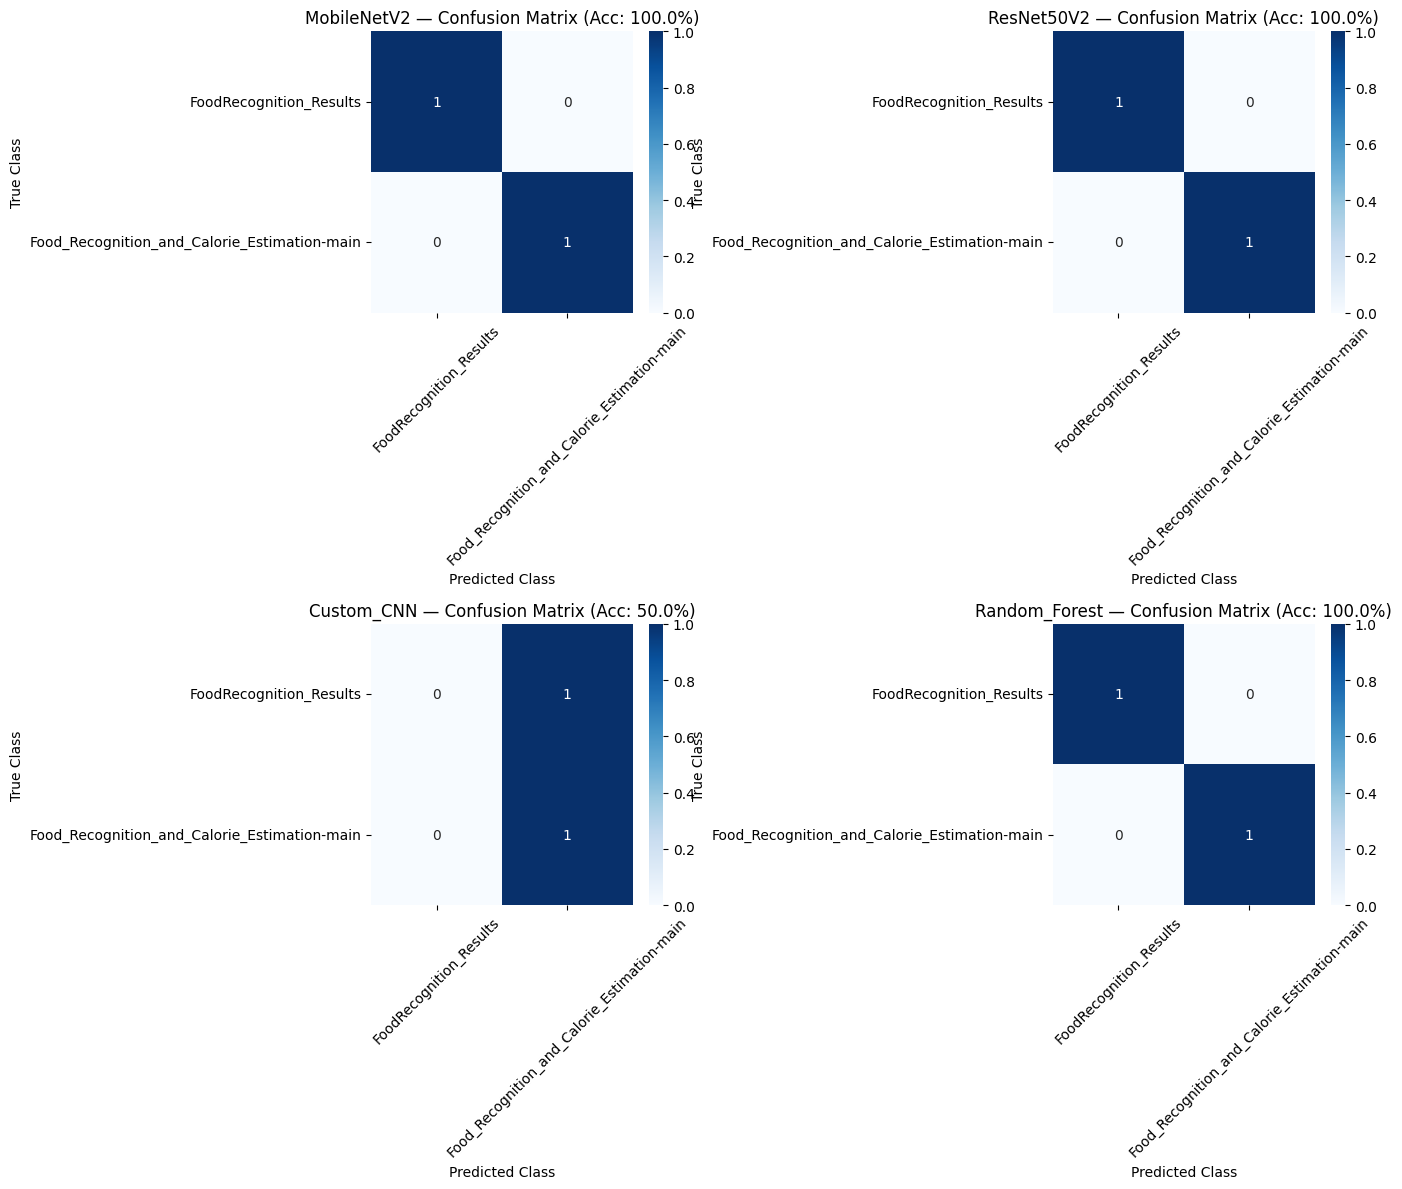

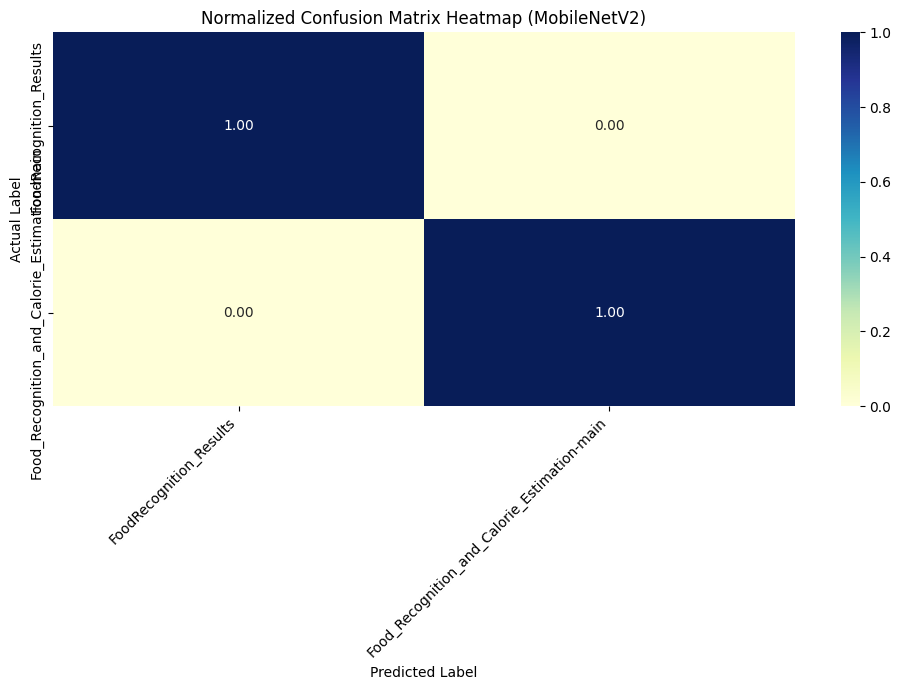

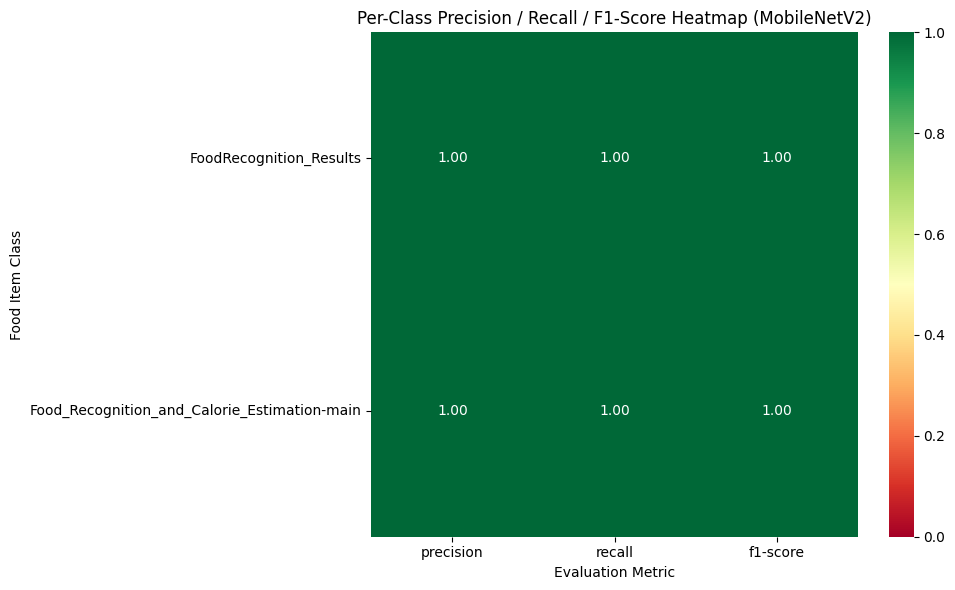

In [ ]:
benchmark_rows = []
for m_name, y_pred in model_predictions.items():
    acc = accuracy_score(y_test_all, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test_all, y_pred, average='weighted', zero_division=0)
    benchmark_rows.append({
        'Model': m_name,
        'Test Accuracy (%)': round(acc * 100, 2),
        'Weighted Precision (%)': round(prec * 100, 2),
        'Weighted Recall (%)': round(rec * 100, 2),
        'Weighted F1-Score (%)': round(f1 * 100, 2)
    })

benchmark_df = pd.DataFrame(benchmark_rows).sort_values(by='Test Accuracy (%)', ascending=False).reset_index(drop=True)
print("\n================ MULTI-MODEL TEST SET LEADERBOARD ================")
display(benchmark_df)

best_model_name = benchmark_df.iloc[0]['Model']
print(f"\n>>> Best Performing Model Automatically Selected: {best_model_name} <<<")

# 1. Plot Side-by-Side Confusion Matrix Heatmaps for ALL 4 Models
fig, axes = plt.subplots(2, 2, figsize=(max(14, len(classes) * 0.8), max(12, len(classes) * 0.7)))
axes = axes.flatten()

for idx, (m_name, y_pred) in enumerate(model_predictions.items()):
    cm = confusion_matrix(y_test_all, y_pred, labels=np.arange(len(classes)))
    sns.heatmap(
        cm, annot=(len(classes) <= 25), fmt='d', cmap='Blues',
        xticklabels=classes, yticklabels=classes, ax=axes[idx]
    )
    acc_val = accuracy_score(y_test_all, y_pred) * 100
    axes[idx].set_title(f"{m_name} — Confusion Matrix (Acc: {acc_val:.1f}%)")
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("True Class")
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(RESULT_DIR / 'all_models_confusion_matrices.png', dpi=150)
plt.show()

# 2. Plot Normalized Percentage Confusion Matrix + Per-Class Precision/Recall/F1 Heatmap for Best Model
best_preds = model_predictions[best_model_name]
cm_best = confusion_matrix(y_test_all, best_preds, labels=np.arange(len(classes)))
cm_norm = cm_best.astype('float') / np.maximum(cm_best.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(max(10, len(classes) * 0.55), max(7, len(classes) * 0.45)))
sns.heatmap(
    cm_norm, annot=(len(classes) <= 25), fmt='.2f', cmap='YlGnBu',
    xticklabels=classes, yticklabels=classes
)
plt.title(f"Normalized Confusion Matrix Heatmap ({best_model_name})")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'best_model_normalized_confusion_matrix.png', dpi=150)
plt.show()

# 3. Per-Class Precision, Recall, F1-Score Heatmap across ALL products/classes
report_dict = classification_report(y_test_all, best_preds, target_names=classes, output_dict=True, zero_division=0)
class_metrics_df = pd.DataFrame(report_dict).T.loc[classes, ['precision', 'recall', 'f1-score']]

plt.figure(figsize=(10, max(6, len(classes) * 0.35)))
sns.heatmap(class_metrics_df, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0.0, vmax=1.0)
plt.title(f"Per-Class Precision / Recall / F1-Score Heatmap ({best_model_name})")
plt.ylabel("Food Item Class")
plt.xlabel("Evaluation Metric")
plt.tight_layout()
plt.savefig(RESULT_DIR / 'per_class_metrics_heatmap.png', dpi=150)
plt.show()

# 8. Complete CSV Nutrition Matcher & Countable Quantity Detector
- Matches predicted classes to your CSV (exact match, common aliases, and fuzzy matching).
- Estimates the **number of countable items/pieces** (e.g., Rotis, Idlis, Dosas, Samosas, Bananas, Gulab Jamuns) using OpenCV watershed/contour segmentation and scales total nutrition accordingly.

In [ ]:
import re
import numpy as np
import cv2
from PIL import Image
from difflib import get_close_matches
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet_v2 import preprocess_input as resnet_preprocess

def normalize_food_name(value):
    value = str(value).lower().strip()
    value = value.replace('&', 'and')
    value = re.sub(r'[^a-z0-9]+', ' ', value)
    return re.sub(r'\s+', ' ', value).strip()

ALIASES = {
    'roti': 'Chappati',
    'chapati': 'Chappati',
    'chapatti': 'Chappati',
    'phulka': 'Chappati',
    'roti chapati': 'Chappati',
    'banana': 'Bananas',
    'pav bhaji': 'Bhaji Pav',
    'pavbhaji': 'Bhaji Pav',
    'idly': 'Idli',
    'medu vada': 'Vada',
}

# Words indicating a food item is typically countable by piece
COUNTABLE_KEYWORDS = {
    'chappati', 'chapati', 'roti', 'paratha', 'puri', 'poori', 'bhatura',
    'idli', 'vada', 'samosa', 'kachori', 'gulab jamun', 'rasgulla', 'laddu',
    'ladoo', 'jalebi', 'dhokla', 'momos', 'pakora', 'tikki', 'aloo tikki',
    'banana', 'bananas', 'egg', 'boiled egg', 'omelette', 'dosa', 'uttapam',
    'naan', 'kulcha', 'thepla', 'cutlet', 'kebabs', 'seekh kebab', 'sandwich'
}

nutrition_lookup_map = {
    normalize_food_name(row['Food_items']): row
    for _, row in nutrition_df.iterrows()
}

def nutrition_lookup(food_name):
    raw = str(food_name).strip()
    norm = normalize_food_name(raw)
    alias_target = ALIASES.get(norm)
    key = normalize_food_name(alias_target) if alias_target else norm

    if key in nutrition_lookup_map:
        return nutrition_lookup_map[key], "Exact/Alias CSV Match"

    # Substring or Fuzzy Match fallback so slight folder naming differences still resolve
    all_keys = list(nutrition_lookup_map.keys())
    for k in all_keys:
        if key in k or k in key:
            return nutrition_lookup_map[k], f"Partial CSV Match ('{nutrition_lookup_map[k]['Food_items']}')"

    close = get_close_matches(key, all_keys, n=1, cutoff=0.6)
    if close:
        return nutrition_lookup_map[close[0]], f"Closest CSV Match ('{nutrition_lookup_map[close[0]]['Food_items']}')"

    return None, "No Match Found"

def is_countable_food(food_name):
    norm = normalize_food_name(food_name)
    return any(kw in norm for kw in COUNTABLE_KEYWORDS)

def estimate_item_count(pil_img, food_name):
    """
    Uses OpenCV contour + watershed distance transform to estimate number of distinct
    food pieces on a plate when the food item is countable.
    """
    countable = is_countable_food(food_name)
    img_rgb = np.array(pil_img.convert('RGB'))
    h, w, _ = img_rgb.shape
    annotated = img_rgb.copy()

    if not countable:
        return 1, False, Image.fromarray(annotated)

    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (7, 7), 0)

    # Otsu thresholding (handle both light background and dark background)
    _, thresh_inv = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    _, thresh_norm = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Pick mask where border pixels are mostly background (0)
    border_inv = np.concatenate([thresh_inv[0, :], thresh_inv[-1, :], thresh_inv[:, 0], thresh_inv[:, -1]])
    mask = thresh_inv if np.mean(border_inv) < 127 else thresh_norm

    kernel = np.ones((5, 5), np.uint8)
    opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)

    # Distance transform to separate touching food items
    dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist_transform, 0.38 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)

    contours, _ = cv2.findContours(sure_fg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    min_area = (h * w) * 0.012
    max_area = (h * w) * 0.90

    valid_boxes = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if min_area <= area <= max_area:
            x, y, bw, bh = cv2.boundingRect(cnt)
            valid_boxes.append((x, y, bw, bh))

    count = max(1, len(valid_boxes))
    for idx, (x, y, bw, bh) in enumerate(valid_boxes, 1):
        cv2.rectangle(annotated, (x, y), (x + bw, y + bh), (0, 230, 0), 3)
        cv2.putText(annotated, f"#{idx}", (x + 5, max(25, y + 25)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 50, 50), 2)

    return count, True, Image.fromarray(annotated)

def predict_with_all_models(pil_img):
    """ Combines ensemble probabilities from MobileNetV2, ResNet50V2, Custom CNN, and Random Forest """
    arr_224 = np.asarray(pil_img.resize(IMG_SIZE), dtype=np.float32)
    batch_m = np.expand_dims(mobilenet_preprocess(arr_224.copy()), axis=0)
    batch_r = np.expand_dims(resnet_preprocess(arr_224.copy()), axis=0)
    batch_c = np.expand_dims(arr_224.copy() / 255.0, axis=0)

    p_m = mobilenet_model.predict(batch_m, verbose=0)[0]
    p_r = resnet_model.predict(batch_r, verbose=0)[0]
    p_c = cnn_model.predict(batch_c, verbose=0)[0]
    feat_m = feature_extractor.predict(batch_m, verbose=0)
    p_rf = rf_clf.predict_proba(feat_m)[0]

    per_model = {
        'MobileNetV2': p_m,
        'ResNet50V2': p_r,
        'Custom_CNN': p_c,
        'Random_Forest': p_rf
    }
    # Weighted ensemble favouring the highest-accuracy transfer learning models
    ensemble_prob = (0.40 * p_m) + (0.35 * p_r) + (0.10 * p_c) + (0.15 * p_rf)
    return ensemble_prob, per_model

# 9. Interactive Food Image Upload, Self-Correction Override & Complete Nutrition Report
Run this cell as many times as you like to test new images!
- Displays predictions from **every model** (`MobileNetV2`, `ResNet50V2`, `Custom_CNN`, `Random_Forest`) + the **Ensemble Verdict**.
- Lets you **confirm or manually override/correct** the food name or piece count if you want to test or fix a prediction.
- Displays **all nutritional fields** from your CSV (`Calories`, `Fats`, `Proteins`, `Carbohydrates`, `Fibre`, `Sugars`, `VitaminD`, `Iron`, `Calcium`, `Sodium`, `Potassium`, etc.) for **1 serving/piece** and **scaled by total quantity**.

Upload a food image...


Saving WhatsApp Image 2026-10-31 at 12.09.17 PM.jpeg to WhatsApp Image 2026-10-31 at 12.09.17 PM (8).jpeg
(Trained models not in memory - type the food name yourself.)


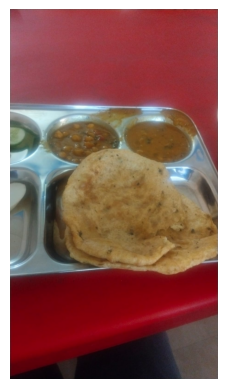

Foods available: burger, butter_naan, chai, chapati, chole_bhature, dal_makhani, dhokla, fried_rice, idli, jalebi, kaathi_rolls, kadai_paneer, kulfi, masala_dosa, momos, paani_puri, pakode, pav_bhaji, pizza, samosa
Food name: chole bhature


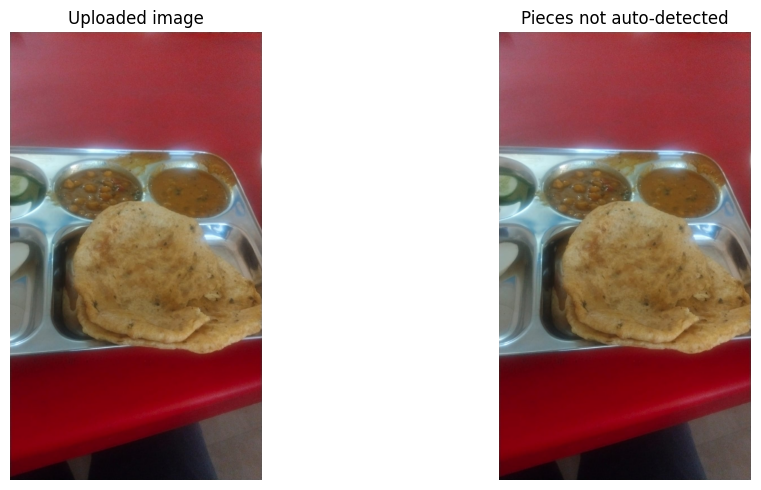

Number of pieces/servings [1] (Enter to accept): 2

===== NUTRITION REPORT: chole bhature x 2 =====

Matched food: chole_bhature  [exact/alias match]   |   Quantity: 2


,Per 1 piece/serving,Total for 2
Nutrient,,
Calories (kcal),450.0,900.0
Protein (g),12.5,25.0
Carbohydrates (g),58.0,116.0
Fat (g),18.5,37.0
Fiber (g),8.0,16.0
Vitamins (mg),6.5,13.0


TOTAL -> Calories: 900.0 kcal | Protein: 25.0 g | Carbs: 116.0 g | Fat: 37.0 g | Fiber: 16.0 g | Vitamins: 13.0 mg


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from difflib import get_close_matches
from google.colab import files

# ---------------------------------------------------------------
# 1. Built-in nutrition database (per 1 standard piece / serving)
# ---------------------------------------------------------------
DEFAULT_NUTRITION_DATA = [
    {"Food_items": "burger",        "Calories": 295, "Protein_g": 17.0, "Carbohydrates_g": 24.0, "Fat_g": 14.0, "Fiber_g": 1.5, "Vitamins_mg": 2.5},
    {"Food_items": "butter_naan",   "Calories": 260, "Protein_g": 7.5,  "Carbohydrates_g": 42.0, "Fat_g": 7.0,  "Fiber_g": 2.0, "Vitamins_mg": 0.4},
    {"Food_items": "chai",          "Calories": 120, "Protein_g": 3.5,  "Carbohydrates_g": 18.0, "Fat_g": 3.8,  "Fiber_g": 0.0, "Vitamins_mg": 0.5},
    {"Food_items": "chapati",       "Calories": 104, "Protein_g": 3.1,  "Carbohydrates_g": 18.0, "Fat_g": 2.5,  "Fiber_g": 2.8, "Vitamins_mg": 0.3},
    {"Food_items": "chole_bhature", "Calories": 450, "Protein_g": 12.5, "Carbohydrates_g": 58.0, "Fat_g": 18.5, "Fiber_g": 8.0, "Vitamins_mg": 6.5},
    {"Food_items": "dal_makhani",   "Calories": 320, "Protein_g": 11.0, "Carbohydrates_g": 34.0, "Fat_g": 15.0, "Fiber_g": 7.5, "Vitamins_mg": 4.0},
    {"Food_items": "dhokla",        "Calories": 160, "Protein_g": 6.0,  "Carbohydrates_g": 25.0, "Fat_g": 4.0,  "Fiber_g": 2.5, "Vitamins_mg": 1.8},
    {"Food_items": "fried_rice",    "Calories": 330, "Protein_g": 7.0,  "Carbohydrates_g": 48.0, "Fat_g": 12.0, "Fiber_g": 3.2, "Vitamins_mg": 8.0},
    {"Food_items": "idli",          "Calories": 65,  "Protein_g": 2.2,  "Carbohydrates_g": 13.5, "Fat_g": 0.4,  "Fiber_g": 1.0, "Vitamins_mg": 0.2},
    {"Food_items": "jalebi",        "Calories": 150, "Protein_g": 1.2,  "Carbohydrates_g": 28.0, "Fat_g": 4.5,  "Fiber_g": 0.3, "Vitamins_mg": 0.1},
    {"Food_items": "kaathi_rolls",  "Calories": 360, "Protein_g": 14.0, "Carbohydrates_g": 40.0, "Fat_g": 16.0, "Fiber_g": 3.5, "Vitamins_mg": 5.5},
    {"Food_items": "kadai_paneer",  "Calories": 340, "Protein_g": 15.0, "Carbohydrates_g": 14.0, "Fat_g": 25.0, "Fiber_g": 3.0, "Vitamins_mg": 18.0},
    {"Food_items": "kulfi",         "Calories": 210, "Protein_g": 5.5,  "Carbohydrates_g": 24.0, "Fat_g": 11.0, "Fiber_g": 0.2, "Vitamins_mg": 1.2},
    {"Food_items": "masala_dosa",   "Calories": 310, "Protein_g": 6.5,  "Carbohydrates_g": 46.0, "Fat_g": 11.5, "Fiber_g": 4.2, "Vitamins_mg": 6.0},
    {"Food_items": "momos",         "Calories": 45,  "Protein_g": 2.0,  "Carbohydrates_g": 6.5,  "Fat_g": 1.2,  "Fiber_g": 0.6, "Vitamins_mg": 1.5},
    {"Food_items": "paani_puri",    "Calories": 36,  "Protein_g": 0.8,  "Carbohydrates_g": 5.5,  "Fat_g": 1.2,  "Fiber_g": 0.7, "Vitamins_mg": 1.0},
    {"Food_items": "pakode",        "Calories": 280, "Protein_g": 7.5,  "Carbohydrates_g": 26.0, "Fat_g": 16.5, "Fiber_g": 4.0, "Vitamins_mg": 4.5},
    {"Food_items": "pav_bhaji",     "Calories": 400, "Protein_g": 10.0, "Carbohydrates_g": 52.0, "Fat_g": 17.5, "Fiber_g": 6.8, "Vitamins_mg": 22.0},
    {"Food_items": "pizza",         "Calories": 285, "Protein_g": 12.0, "Carbohydrates_g": 36.0, "Fat_g": 10.4, "Fiber_g": 2.5, "Vitamins_mg": 3.2},
    {"Food_items": "samosa",        "Calories": 262, "Protein_g": 4.5,  "Carbohydrates_g": 32.0, "Fat_g": 13.0, "Fiber_g": 2.6, "Vitamins_mg": 3.8},
]

# Fields shown in the report: (column, label, unit)
REPORT_FIELDS = [
    ("Calories",        "Calories",      "kcal"),
    ("Protein_g",       "Protein",       "g"),
    ("Carbohydrates_g", "Carbohydrates", "g"),
    ("Fat_g",           "Fat",           "g"),
    ("Fiber_g",         "Fiber",         "g"),
    ("Vitamins_mg",     "Vitamins",      "mg"),
]

def norm(s):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", str(s).lower())).strip()

BUILTIN = {norm(r["Food_items"]): r for r in DEFAULT_NUTRITION_DATA}

ALIASES = {
    "roti": "chapati", "chappati": "chapati", "phulka": "chapati",
    "naan": "butter naan", "dosa": "masala dosa",
    "pakora": "pakode", "pakoda": "pakode", "bhajiya": "pakode",
    "pani puri": "paani puri", "panipuri": "paani puri", "golgappa": "paani puri",
    "pavbhaji": "pav bhaji", "bhaji pav": "pav bhaji",
    "idly": "idli", "momo": "momos", "dumpling": "momos",
    "tea": "chai", "masala chai": "chai",
    "kathi roll": "kaathi rolls", "kaathi roll": "kaathi rolls", "kati roll": "kaathi rolls",
    "chole bhatura": "chole bhature", "dal makhni": "dal makhani",
    "paneer kadai": "kadai paneer",
}

def lookup_food(name):
    """Returns (dict with report fields, matched_name, how) or (None, None, reason)."""
    key = ALIASES.get(norm(name), norm(name))
    if key in BUILTIN:
        r = BUILTIN[key]
        return r, r["Food_items"], "exact/alias match"
    for k in BUILTIN:
        if key and (key in k or k in key):
            return BUILTIN[k], BUILTIN[k]["Food_items"], "partial match"
    close = get_close_matches(key, list(BUILTIN), n=1, cutoff=0.6)
    if close:
        r = BUILTIN[close[0]]
        return r, r["Food_items"], "closest match"
    # Fallback: your CSV (if cell 3/8 were run) mapped to the same six fields
    if "nutrition_lookup" in globals():
        try:
            row, how = nutrition_lookup(name)
            if row is not None:
                mapped = {
                    "Calories": float(row["Calories"]), "Protein_g": float(row["Proteins"]),
                    "Carbohydrates_g": float(row["Carbohydrates"]), "Fat_g": float(row["Fats"]),
                    "Fiber_g": float(row["Fibre"]), "Vitamins_mg": float(row["VitaminD"]),
                }
                return mapped, row["Food_items"], "CSV " + how
        except Exception:
            pass
    return None, None, "no match"

# ---------------------------------------------------------------
# 2. Optional: model predictions (skipped if runtime was reset)
# ---------------------------------------------------------------
MODELS_READY = all(n in globals() for n in
                   ["mobilenet_model", "resnet_model", "cnn_model",
                    "feature_extractor", "rf_clf", "classes", "predict_with_all_models"])

def show_report(food, count):
    rec, matched, how = lookup_food(food)
    if rec is None:
        print(f"\nNo nutrition data found for '{food}'.")
        print("Built-in foods:", ", ".join(r["Food_items"] for r in DEFAULT_NUTRITION_DATA))
        return
    rows = []
    for col, label, unit in REPORT_FIELDS:
        one = float(rec[col])
        rows.append({
            "Nutrient": f"{label} ({unit})",
            "Per 1 piece/serving": round(one, 2),
            f"Total for {count}": round(one * count, 2),
        })
    print(f"\nMatched food: {matched}  [{how}]   |   Quantity: {count}")
    display(pd.DataFrame(rows).set_index("Nutrient"))
    tot = {label: float(rec[col]) * count for col, label, _ in REPORT_FIELDS}
    print("TOTAL -> "
          f"Calories: {tot['Calories']:.1f} kcal | Protein: {tot['Protein']:.1f} g | "
          f"Carbs: {tot['Carbohydrates']:.1f} g | Fat: {tot['Fat']:.1f} g | "
          f"Fiber: {tot['Fiber']:.1f} g | Vitamins: {tot['Vitamins']:.1f} mg")

def run_once():
    print("Upload a food image...")
    up = files.upload()
    if not up:
        print("No file uploaded.")
        return
    img = Image.open(next(iter(up))).convert("RGB")

    if MODELS_READY:
        ens_prob, per_model = predict_with_all_models(img)
        rows = []
        for m, p in per_model.items():
            i = int(np.argmax(p))
            rows.append({"Model": m, "Prediction": classes[i], "Confidence (%)": round(float(p[i]) * 100, 2)})
        e = int(np.argmax(ens_prob))
        rows.append({"Model": "ENSEMBLE", "Prediction": classes[e], "Confidence (%)": round(float(ens_prob[e]) * 100, 2)})
        display(pd.DataFrame(rows))
        guess = classes[e]
        ans = input(f"\nPredicted: '{guess}'. Press Enter to accept or type the correct food name: ").strip()
        food = ans if ans else guess
    else:
        print("(Trained models not in memory - type the food name yourself.)")
        plt.imshow(img); plt.axis("off"); plt.show()
        print("Foods available:", ", ".join(r["Food_items"] for r in DEFAULT_NUTRITION_DATA))
        food = ""
        while not food:
            food = input("Food name: ").strip()

    # Piece counting (uses cell 8's detector if available)
    count, countable, annotated = 1, False, img
    if "estimate_item_count" in globals():
        try:
            count, countable, annotated = estimate_item_count(img, food)
        except Exception:
            pass
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(img); ax[0].set_title("Uploaded image"); ax[0].axis("off")
    ax[1].imshow(annotated)
    ax[1].set_title(f"Detected pieces: {count}" if countable else "Pieces not auto-detected")
    ax[1].axis("off"); plt.tight_layout(); plt.show()

    c_in = input(f"Number of pieces/servings [{count}] (Enter to accept): ").strip()
    if c_in.isdigit() and int(c_in) > 0:
        count = int(c_in)

    print(f"\n===== NUTRITION REPORT: {food} x {count} =====")
    show_report(food, count)

run_once()